# Downstream RQ2 — Colab Pro **v2** (L1 head, không Qwen)

**Paper chính (18 jobs):** tfidf + phobert + xlmr × 6 methods → `results/downstream_v2_reeval/`.

**Không chạy Qwen** trên T4/L4 (OOM / quá lâu). Mistral là tùy chọn (Stage B).

**Upload 1 lần:** §0 + [`COLAB_V2_UPLOAD_NOTE.md`](COLAB_V2_UPLOAD_NOTE.md).  
**Runner:** `experiments/annotation_benchmark/colab_downstream_v2.py`

### Flow
1. §1 Install → §2 Mount → `--check-upload`
2. §3b smoke import
3. §3: `RUN_STAGE_A=True` → §4 Run (**~vài giờ** trên T4/L4)
4. (Tuỳ chọn) §3: `RUN_STAGE_MISTRAL=True`, HF token §2b → §4 lại
5. §5 xem CSV + bảng paper
6. Test nhanh: `RUN_SMOKE=True` (1 epoch)


## 0. Upload checklist (1 lần lên Drive)

Chi tiết đầy đủ: [`COLAB_V2_UPLOAD_NOTE.md`](COLAB_V2_UPLOAD_NOTE.md)

### Code (bắt buộc — hay thiếu trên Drive)
```
experiments/annotation_benchmark/colab_downstream_v2.py
experiments/annotation_benchmark/run_downstream.py
experiments/annotation_benchmark/common.py
experiments/evaluation/utils.py
experiments/evaluation/train_tfidf_svm.py
experiments/evaluation/train_transformer.py
experiments/evaluation/lora_utils.py
experiments/phase5_pipeline/pipeline_utils.py
```

### Data (bắt buộc)
```
data/datasets/{zero_shot,few_shot,cot,freeal,candist,verified_d2}_dataset.json
data/datasets/d2_verified_train.json
data/gold/d3_dataset.json
data/splits/d3_val_ids.txt
data/splits/d3_test_ids.txt
```

### Nên có
```
data/unified_intents.csv
data/intent_kb.intent_edges_28_05_2026.csv
notebooks/downstream_colab_pro_v2.ipynb
notebooks/COLAB_V2_UPLOAD_NOTE.md
```

Sau §2 mount, chạy cell `--check-upload` ngay bên dưới paths.


## 1. Install packages

In [9]:
!pip -q install -U "transformers>=4.51.0" peft accelerate scikit-learn pandas tqdm sentencepiece matplotlib huggingface_hub

import torch, transformers, peft
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("peft:", peft.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
else:
    print("⚠️ Không có GPU — classifier DL sẽ chậm. Vẫn chạy được tfidf.")

assert tuple(map(int, transformers.__version__.split(".")[:2])) >= (4, 51), \
    "Cần transformers>=4.51. Restart runtime rồi chạy lại cell này."


^C
torch: 2.8.0
transformers: 5.14.1
peft: 0.19.1
CUDA: False
⚠️ Không có GPU — classifier DL sẽ chậm. Vẫn chạy được tfidf.


## 2. Mount Drive + paths

Đổi `DEFAULT_DRIVE_REPO` nếu folder trên Drive khác.

In [ ]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DEFAULT_DRIVE_REPO = "/content/drive/MyDrive/intent_kb"
OUTDIR_REL = "experiments/annotation_benchmark/results/downstream_v2_reeval"

if IN_COLAB:
    if not Path("/content/drive/MyDrive").exists():
        from google.colab import drive
        drive.mount("/content/drive")
    REPO_ROOT = Path(DEFAULT_DRIVE_REPO)
else:
    REPO_ROOT = Path("..").resolve()

os.chdir(REPO_ROOT)
os.environ["INTENT_REPO_ROOT"] = str(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT / "experiments" / "annotation_benchmark"))
sys.path.insert(0, str(REPO_ROOT / "experiments" / "evaluation"))

DATASETS = REPO_ROOT / "data/datasets"
D3 = REPO_ROOT / "data/gold/d3_dataset.json"
RESULTS = REPO_ROOT / OUTDIR_REL
RESULTS.mkdir(parents=True, exist_ok=True)
RUNNER = REPO_ROOT / "experiments/annotation_benchmark/colab_downstream_v2.py"
BUILD_TABLE = REPO_ROOT / "experiments/annotation_benchmark/build_rq2_reeval_table.py"

print("REPO_ROOT:", REPO_ROOT)
print("RUNNER   :", "✅" if RUNNER.exists() else "❌", RUNNER)
print("D3       :", "✅" if D3.exists() else "❌", D3)
print("OUTDIR   :", RESULTS)
print("Upload note:", (REPO_ROOT / "notebooks/COLAB_V2_UPLOAD_NOTE.md").exists())
assert RUNNER.exists(), "Thiếu colab_downstream_v2.py — sync nhóm B (code) lên Drive."


Mounted at /content/drive
REPO_ROOT: /content/drive/MyDrive/intent_kb
RUNNER   : ✅ /content/drive/MyDrive/intent_kb/experiments/annotation_benchmark/colab_downstream_v2.py
D3       : ✅ /content/drive/MyDrive/intent_kb/data/gold/d3_dataset.json
Results  : /content/drive/MyDrive/intent_kb/experiments/annotation_benchmark/results
Upload note: False


In [ ]:
# Phải toàn ✅ trước khi train
!python experiments/annotation_benchmark/colab_downstream_v2.py --check-upload


REPO: /content/drive/MyDrive/intent_kb
=== REQUIRED (B+C+A) ===
  ✅ [B-code] experiments/annotation_benchmark/colab_downstream_v2.py
  ✅ [B-code] experiments/annotation_benchmark/run_downstream.py
  ✅ [B-code] experiments/annotation_benchmark/common.py
  ✅ [B-code] experiments/evaluation/utils.py
  ✅ [B-code] experiments/evaluation/train_tfidf_svm.py
  ✅ [B-code] experiments/evaluation/train_transformer.py
  ✅ [B-code] experiments/evaluation/lora_utils.py
  ❌ [B-code] experiments/phase5_pipeline/pipeline_utils.py
  ✅ [C-data] data/datasets/zero_shot_dataset.json
  ✅ [C-data] data/datasets/few_shot_dataset.json
  ✅ [C-data] data/datasets/cot_dataset.json
  ✅ [C-data] data/datasets/freeal_dataset.json
  ✅ [C-data] data/datasets/candist_dataset.json
  ✅ [C-data] data/datasets/verified_d2_dataset.json
  ✅ [C-data] data/datasets/d2_verified_train.json
  ✅ [C-data] data/gold/d3_dataset.json
  ✅ [C-data] data/splits/d3_val_ids.txt
  ✅ [C-data] data/splits/d3_test_ids.txt
  ❌ [A-nb] notebooks/

## 2b. Hugging Face login (chỉ khi chạy Mistral)

Bỏ qua section này nếu chỉ chạy **Stage A** (tfidf + phobert + xlmr).

`mistralai/Mistral-7B-v0.3` là **gated model** — cần khi `RUN_STAGE_MISTRAL=True`.

1. Token: https://huggingface.co/settings/tokens  
2. Accept license: https://huggingface.co/mistralai/Mistral-7B-v0.3  
3. Dán token dưới hoặc Colab Secret `HF_TOKEN`.

**Qwen3 không dùng** trong notebook này (T4/L4 thường không chạy nổi).

In [ ]:
import os
from pathlib import Path

# Chỉ cần khi RUN_STAGE_MISTRAL=True (§3). Bỏ qua nếu chỉ Stage A.
HF_TOKEN = ""
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN") or ""
except Exception:
    pass
if not HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

# Nếu chưa có: dán token vào đây (đừng commit token lên git)
# HF_TOKEN = "hf_..."

if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    os.environ["HUGGING_FACE_HUB_TOKEN"] = HF_TOKEN
    from huggingface_hub import login
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("✅ HF login OK — Mistral tải được")
else:
    print("⚠️ Chưa có HF_TOKEN — OK nếu chỉ RUN_STAGE_A (tfidf/phobert/xlmr).")
    print("   Mistral sẽ FAIL nếu bật RUN_STAGE_MISTRAL.")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


✅ HF login OK — Mistral tải được


## 3. Config — chọn stage

| Flag | Preset | Jobs | Khi nào |
|---|---|---:|---|
| `RUN_SMOKE=True` | smoke | 2 | Test pipeline ~5 phút |
| **`RUN_STAGE_A=True`** | rq2_light | **18** | **Paper chính** (tfidf+phobert+xlmr) |
| `RUN_STAGE_MISTRAL=True` | rq2_mistral | +6 | Tuỳ chọn, cần §2b HF, overnight T4 |

- `verified_d2` train = `d2_verified_train.json` (~1454 rows)  
- Decoding = `marginal`, L1 head = **on**  
- **Không có Qwen** — bỏ qua Stage B trong plan gốc

GPU T4/L4: chỉ cần `RUN_STAGE_A=True` là đủ cho bảng RQ2 (3 classifiers × 6 methods).


In [ ]:
# ── RQ2 v2 re-eval — không Qwen ───────────────────────────────────────────────
OUTDIR = OUTDIR_REL  # set ở §2
DECODING = "marginal"
EXTRA_FLAGS = ""  # vd: --lambda-l1 0.5

# Bật/tắt từng stage (chạy §4 sau khi chỉnh)
RUN_SMOKE = False          # smoke: verified_d2, tfidf+phobert, 1 epoch
RUN_STAGE_A = True         # ← paper: tfidf+phobert+xlmr × 6 methods (18 rows)
RUN_STAGE_MISTRAL = False  # optional: +6 rows, cần HF token §2b

STAGES: list[tuple[str, bool]] = []
if RUN_SMOKE:
    STAGES.append(("smoke", False))
if RUN_STAGE_A:
    STAGES.append(("rq2_light", False))
if RUN_STAGE_MISTRAL:
    STAGES.append(("rq2_mistral", True))

if not STAGES:
    raise ValueError("Bật ít nhất một trong RUN_SMOKE / RUN_STAGE_A / RUN_STAGE_MISTRAL")

print("OUTDIR   :", OUTDIR)
print("DECODING :", DECODING)
print("STAGES   :", STAGES)
print("Expected rows (approx):", end=" ")
if RUN_SMOKE:
    print("2 (smoke)", end=" ")
if RUN_STAGE_A:
    print("+18 (light)", end=" ")
if RUN_STAGE_MISTRAL:
    print("+6 (mistral)", end=" ")
print()
print("EXTRA    :", EXTRA_FLAGS or "(none)")


PRESET   : lora ← qwen3 + mistral
DECODING : marginal
APPEND   : True
EXTRA    : (none)

Lệnh §4:
  python experiments/annotation_benchmark/colab_downstream_v2.py --preset lora --decoding marginal --append 


In [ ]:
import subprocess

# Audit dataset + paths (không train)
subprocess.run(
    [sys.executable, str(RUNNER), "--preset", "rq2_light", "--audit-only"],
    cwd=str(REPO_ROOT),
)


CompletedProcess(args=['/usr/bin/python3', '/content/drive/MyDrive/intent_kb/experiments/annotation_benchmark/colab_downstream_v2.py', '--preset', 'lora', '--audit-only'], returncode=0)

## 3b. Smoke test import (bắt buộc trước §4)

Nếu FAIL → sync code nhóm B lên Drive (`common.py`, `run_downstream.py`, `train_transformer.py`).

In [ ]:
import importlib.util
import sys

spec = importlib.util.spec_from_file_location(
    "common_smoke",
    REPO_ROOT / "experiments/annotation_benchmark/common.py",
)
mod = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = mod
spec.loader.exec_module(mod)
print("✅ common.py OK — METHODS:", mod.METHODS)

eval_dir = str(REPO_ROOT / "experiments/evaluation")
bench_dir = str(REPO_ROOT / "experiments/annotation_benchmark")
for p in (bench_dir, eval_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

spec2 = importlib.util.spec_from_file_location(
    "rd_smoke",
    REPO_ROOT / "experiments/annotation_benchmark/run_downstream.py",
)
rd = importlib.util.module_from_spec(spec2)
sys.modules[spec2.name] = rd
spec2.loader.exec_module(rd)
print("✅ run_downstream.py OK")
print("   classifiers:", [k for k in rd.ALL_CLASSIFIER_KEYS if k != "qwen3"], "+ qwen3 (skip)")
print("   verified_d2 train:", rd.METHOD_TRAIN_PATH.get("verified_d2"))
print("→ OK — chạy §4 với RUN_STAGE_A=True")


✅ common.py OK — METHODS: ['zero_shot', 'few_shot', 'cot', 'freeal', 'candist', 'verified_d2']
✅ run_downstream.py OK — classifiers: ['tfidf', 'phobert', 'xlmr', 'qwen3', 'mistral']
   qwen3 model: Qwen/Qwen3-1.7B
   decoding choices: argmax | marginal; extra method: verified_d2_clean
→ Nếu thấy 2 dòng ✅ trên, chạy §4 với PRESET phù hợp (v2).


## 4. Run downstream (theo STAGES ở §3)

Chạy lần lượt từng preset trong `STAGES`. Stage đầu ghi đè CSV; các stage sau dùng `--append`.

Log: `{OUTDIR}/logs/`  
Thời gian T4/L4: Stage A ~ vài giờ; Mistral (nếu bật) → overnight.


In [ ]:
import subprocess

failed: list[str] = []
for preset, append in STAGES:
    cmd = [
        sys.executable,
        str(RUNNER),
        "--preset",
        preset,
        "--decoding",
        DECODING,
        "--outdir",
        OUTDIR,
        "--l1-head",
    ]
    cmd.append("--append" if append else "--no-append")
    if EXTRA_FLAGS.strip():
        cmd.extend(EXTRA_FLAGS.split())

    print("\n" + "=" * 70)
    print("RUN:", " ".join(cmd))
    proc = subprocess.run(cmd, cwd=str(REPO_ROOT))
    print("exit:", proc.returncode)
    if proc.returncode != 0:
        failed.append(preset)

if failed:
    raise RuntimeError(f"Runner failed for: {failed} — xem {OUTDIR}/logs/")
print("\n✅ Done — CSV:", f"{OUTDIR}/downstream_performance.csv")


RUN: /usr/bin/python3 /content/drive/MyDrive/intent_kb/experiments/annotation_benchmark/colab_downstream_v2.py --preset lora --decoding marginal --append
exit: 0


## 4b. One-shot (tuỳ chọn)

Chỉ chạy **một** preset thủ công — ví dụ resume sau OOM:

```python
!python experiments/annotation_benchmark/colab_downstream_v2.py \
  --preset rq2_light --decoding marginal --l1-head \
  --outdir experiments/annotation_benchmark/results/downstream_v2_reeval --append
```

In [ ]:
RUN_ONE_SHOT = False  # True = chạy 1 lệnh thay vì vòng §4

if RUN_ONE_SHOT:
    # One-shot dùng 1 batch chung — lấy batch nhỏ nhất trong list (an toàn cho mistral)
    bs_common = min(
        (BATCH_BY_CLF[c] for c in CLASSIFIERS.split(",") if c.strip() != "tfidf" and BATCH_BY_CLF.get(c.strip(), 0) > 0),
        default=8,
    )
    cmd = (
        f"python experiments/annotation_benchmark/run_downstream.py "
        f"--method {METHODS_ARG} "
        f"--classifiers {CLASSIFIERS} "
        f"--epochs {EPOCHS} "
        f"--batch-size {bs_common} "
        f"--decoding {DECODING} "
        + ("--append" if APPEND else "")
    )
    print(cmd)
    !{cmd}
else:
    print("SKIP one-shot (dùng §4). Đặt RUN_ONE_SHOT=True nếu muốn.")


SKIP one-shot (dùng §4). Đặt RUN_ONE_SHOT=True nếu muốn.


## 5. Xem kết quả + bảng paper

CSV: `downstream_v2_reeval/downstream_performance.csv`  
Sau Stage A đủ **18 rows** cho paper (3 classifiers × 6 methods).

,training_dataset,classifier,l3_accuracy,l3_macro_f1,full_path_accuracy
0,Zero-shot,TF-IDF+SVM,0.095,0.0392,0.040
1,Zero-shot,PhoBERT (vinai/phobert-base),0.055,0.0123,0.035
2,Zero-shot,XLM-RoBERTa (FacebookAI/xlm-roberta-base),0.055,0.0099,0.040
3,Few-shot,TF-IDF+SVM,0.080,0.0256,0.040
4,Few-shot,PhoBERT (vinai/phobert-base),0.060,0.0106,0.030
5,Few-shot,XLM-RoBERTa (FacebookAI/xlm-roberta-base),0.045,0.0082,0.030
6,CoT,TF-IDF+SVM,0.105,0.0386,0.065
7,CoT,PhoBERT (vinai/phobert-base),0.055,0.0125,0.035
8,CoT,XLM-RoBERTa (FacebookAI/xlm-roberta-base),0.055,0.0093,0.040
9,FreeAL (LLM-only),TF-IDF+SVM,0.165,0.0822,0.130



L3 Macro-F1:


classifier,Mistral-7B-LoRA (mistralai/Mistral-7B-v0.3),PhoBERT (vinai/phobert-base),Qwen3-1.7B-LoRA (Qwen/Qwen3-1.7B),TF-IDF+SVM,XLM-RoBERTa (FacebookAI/xlm-roberta-base)
training_dataset,,,,,
CanDist (LLM-only),0.0335,0.0124,0.0060,0.0335,0.0140
CoT,0.0365,0.0125,0.0295,0.0386,0.0093
Cross-Verified Hierarchical Intent Labeling (Ours),0.0963,0.0002,0.0873,0.1197,0.0743
Few-shot,0.0286,0.0106,0.0291,0.0256,0.0082
FreeAL (LLM-only),0.0931,0.0386,0.0458,0.0822,0.0256
Zero-shot,0.0380,0.0123,0.0244,0.0392,0.0099



Full-path Accuracy:


classifier,Mistral-7B-LoRA (mistralai/Mistral-7B-v0.3),PhoBERT (vinai/phobert-base),Qwen3-1.7B-LoRA (Qwen/Qwen3-1.7B),TF-IDF+SVM,XLM-RoBERTa (FacebookAI/xlm-roberta-base)
training_dataset,,,,,
CanDist (LLM-only),0.040,0.025,0.025,0.070,0.025
CoT,0.065,0.035,0.050,0.065,0.040
Cross-Verified Hierarchical Intent Labeling (Ours),0.135,0.005,0.120,0.175,0.165
Few-shot,0.045,0.030,0.045,0.040,0.030
FreeAL (LLM-only),0.125,0.085,0.080,0.130,0.095
Zero-shot,0.055,0.035,0.040,0.040,0.040


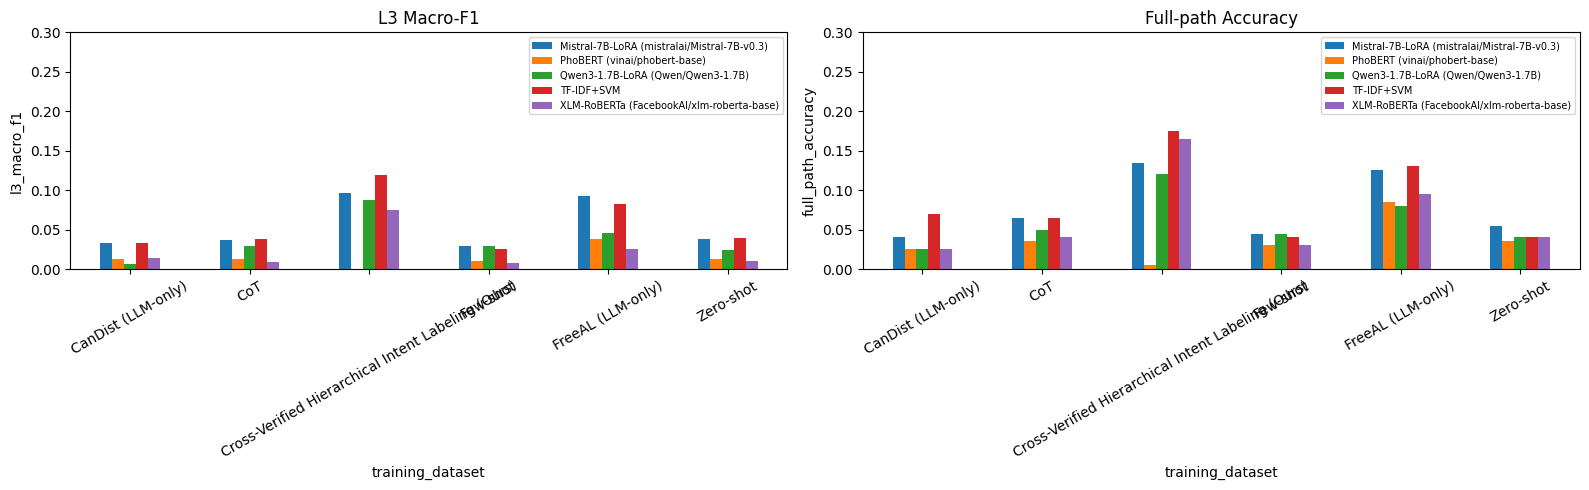

Saved figure → /content/drive/MyDrive/intent_kb/experiments/annotation_benchmark/results/downstream_compare_20260725_013528.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import display

if "STAMP" not in globals():
    STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

csv_path = RESULTS / "downstream_performance.csv"
if not csv_path.exists():
    print("Chưa có", csv_path)
    print("Chạy §4 với RUN_STAGE_A=True trước.")
else:
    df = pd.read_csv(csv_path)
    print(f"Rows: {len(df)} (paper Stage A = 18, +mistral = 24)")
    cols = [
        "training_dataset",
        "classifier",
        "n_train",
        "use_l1_head",
        "l1_accuracy",
        "l3_accuracy",
        "l3_macro_f1",
        "full_path_accuracy",
    ]
    display(df[cols].round(4))

    for metric, title in [
        ("l3_macro_f1", "L3 Macro-F1"),
        ("full_path_accuracy", "Full-path Accuracy"),
    ]:
        pivot = df.pivot_table(
            index="training_dataset", columns="classifier", values=metric, aggfunc="first"
        )
        print(f"\n{title}:")
        display(pivot.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric, title in [
        (axes[0], "l3_macro_f1", "L3 Macro-F1"),
        (axes[1], "full_path_accuracy", "Full-path Accuracy"),
    ]:
        p = df.pivot_table(
            index="training_dataset", columns="classifier", values=metric, aggfunc="first"
        )
        p.plot(kind="bar", ax=ax, rot=30)
        ax.set_title(title)
        ax.set_ylabel(metric)
        ax.legend(fontsize=7, loc="best")
        ymax = float(p.max().max()) if p.size else 0.3
        ax.set_ylim(0, max(0.3, ymax * 1.25))
    plt.tight_layout()
    out_fig = RESULTS / f"downstream_compare_{STAMP}.png"
    plt.savefig(out_fig, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved figure →", out_fig)

# Bảng paper (markdown + JSON)
if BUILD_TABLE.exists() and csv_path.exists():
    subprocess.run(
        [
            sys.executable,
            str(BUILD_TABLE),
            "--csv",
            str(csv_path),
            "--outdir",
            str(RESULTS),
        ],
        cwd=str(REPO_ROOT),
        check=False,
    )
    print("Table →", RESULTS / "rq2_reeval_table.md")

## 6. Tips

| GPU | Stage A (rq2_light) | Mistral (optional) |
|---|---|---|
| T4 16GB | ~3–5h | overnight |
| L4 24GB | ~2–4h | ~4–8h |

1. **Chỉ cần paper:** `RUN_STAGE_A=True`, các flag khác `False`
2. **Không chạy Qwen** — bỏ qua `rq2_qwen` / `rq2_full`
3. OOM phobert/xlmr → giảm `BATCH_BY_CLF` trong `colab_downstream_v2.py`, sync Drive
4. Resume: `ONE_SHOT_PRESET="rq2_light"`, `ONE_SHOT_APPEND=True` ở §4b
5. Upload: §0 / `COLAB_V2_UPLOAD_NOTE.md`
